# Lab 3-03: Token Streaming & LLM Inference Latency Metrics (TTFT, ITL, Throughput)

**Chapter 3: Software Development for Generative AI and LLMs**  
**Lab Type:** Hosted-API Lab | **Estimated Time:** 40–50 minutes  
**Exam Domains Covered:** Software Development (24%), Core ML & AI Knowledge (30%)

---

## Learning Objectives
By the end of this lab, you will be able to:
1. Call a hosted LLM endpoint with both **blocking (`stream=False`)** and **Server-Sent Events streaming (`stream=True`)** modes using the OpenAI-compatible SDK.
2. Define, measure, and calculate the four foundational LLM serving metrics tested on the NCA-GENL exam:
   - **Time to First Token (TTFT)**
   - **Inter-Token Latency (ITL) / Time Per Output Token (TPOT)**
   - **End-to-End (E2E) Request Latency**
   - **Output Token Throughput ($\text{tokens/sec}$)**
3. Explain why the **Prefill Phase** (compute-bound) governs **TTFT**, why the **Decode Phase** (memory-bandwidth-bound) governs **ITL**, and why `stream=True` dramatically improves **perceived user responsiveness** without reducing total generation time.

---
## 1. Conceptual Foundation: Prefill vs. Decode & The Four Latency Metrics

In **Chapter 3 (*Streaming Responses and Latency Metrics*)** and **Chapter 8 (*Inference Optimization*)**, LLM inference is divided into two distinct computational phases:

| Inference Phase | What Happens | Hardware Bottleneck | Governed Metric |
| :--- | :--- | :--- | :--- |
| **1. Prefill Phase** | Processes all input prompt tokens **in parallel** in a single forward pass to populate the initial **KV Cache** and emit the **1st output token** | **Compute-bound** (Matrix-Matrix multiplication on Tensor Cores) | **Time to First Token (TTFT)** |
| **2. Decode Phase** | Generates subsequent tokens **autoregressively one token at a time**, reading all model weights + KV cache from VRAM for each step | **Memory-bandwidth-bound** (Matrix-Vector operations limited by HBM read speed) | **Inter-Token Latency (ITL)** |

### Key Equations
Let $t_{\text{send}}$ be the timestamp when the request is sent, $t_1$ be when the **first token** arrives, $t_N$ be when the **$N$-th (final) token** arrives, and $N$ be the total number of generated tokens:
$$\text{TTFT} = t_1 - t_{\text{send}}$$
$$\text{End-to-End Latency (E2E)} = t_N - t_{\text{send}} = \text{TTFT} + \sum_{i=2}^{N} (t_i - t_{i-1})$$
$$\text{Mean Inter-Token Latency (ITL)} = \frac{t_N - t_1}{N - 1} = \frac{\text{E2E} - \text{TTFT}}{N - 1}$$
$$\text{Decode Throughput (tok/s)} = \frac{N - 1}{t_N - t_1} \approx \frac{1}{\text{ITL}}$$

> **EXAM TIP (Chapter 3):** Why enable `stream=True` in a chat UI?
> - With `stream=False`, the user stares at a blank spinner for the entire **End-to-End Latency** (e.g., 3.5 seconds for a 150-token answer).
> - With `stream=True`, the user begins reading the answer as soon as **TTFT** elapses (e.g., 220 ms!), and tokens arrive faster than human reading speed (~15–25 ms per token vs. ~200 ms human reading speed per word).
> - **Crucial Distinction:** Enabling `stream=True` improves **perceived latency (TTFT visibility)**; it does **not** make the GPU compute the final token faster!

In [1]:
import os
# Prevent Windows Anaconda + PyTorch OpenMP (libiomp5md.dll) kernel crash:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NIM_BASE_URL = "https://integrate.api.nvidia.com/v1"
MODEL_NAME = "google/gemma-4-31b-it"
API_KEY_AVAILABLE = bool(os.environ.get("NVIDIA_API_KEY", "").startswith("nvapi-"))
print(f"Live NVIDIA NIM Streaming Mode: {API_KEY_AVAILABLE} (Model: {MODEL_NAME})")

Live NVIDIA NIM Streaming Mode: False (Model: google/gemma-4-31b-it)


---
## 2. Benchmarking `stream=False` (Blocking) vs. `stream=True` (SSE Token Streaming)

Let's write two instrumented benchmark functions:
1. `measure_non_streaming_call()`: Calls `client.chat.completions.create(..., stream=False)`. Notice that the first byte of text does not arrive until the **entire completion** is finished (`time_to_first_visible_text == E2E_latency`).
2. `measure_streaming_call()`: Calls `client.chat.completions.create(..., stream=True)` and records a high-resolution `time.perf_counter()` timestamp on **every incoming token chunk**.

In [2]:
def measure_non_streaming_call(prompt: str, max_tokens: int = 1024) -> dict:
    messages = [
        {"role": "system", "content": "You are a technical instructor. Answer clearly in 4-5 sentences."},
        {"role": "user", "content": prompt},
    ]
    t_send = time.perf_counter()
    text = None
    n_tokens = None

    if API_KEY_AVAILABLE:
        try:
            from openai import OpenAI
            client = OpenAI(base_url=NIM_BASE_URL, api_key=os.environ["NVIDIA_API_KEY"])
            resp = client.chat.completions.create(
                model=MODEL_NAME,
                messages=messages,
                temperature=0.2,
                max_tokens=max_tokens,
                stream=False,
            )
            t_done = time.perf_counter()
            time.sleep(1.5)
            msg = resp.choices[0].message if resp.choices else None
            if msg is not None:
                text = getattr(msg, "content", None) or getattr(msg, "reasoning_content", None)
            if text:
                n_tokens = resp.usage.completion_tokens if getattr(resp, "usage", None) else len(text.split())
        except Exception as e:
            print(f"[WARN] Non-streaming call fallback ({type(e).__name__})")

    if not text:
        # Realistic blocking call latency simulation (TTFT 210ms + 75 tokens * 14.5ms/token)
        simulated_tokens = (
            "In Large Language Model serving, the Prefill phase processes all input prompt tokens in parallel "
            "using dense matrix-matrix multiplications on GPU Tensor Cores, which determines Time to First Token (TTFT). "
            "Once the first token is emitted and the KV Cache is populated, the Decode phase generates one token at a "
            "time autoregressively. Because each decode step must read model weights from HBM memory, decode is "
            "memory-bandwidth bound and determines Inter-Token Latency (ITL)."
        ).split()
        n_tokens = len(simulated_tokens)
        sim_wait = 0.210 + n_tokens * 0.0145
        time.sleep(min(sim_wait, 0.35))
        t_done = t_send + sim_wait
        text = " ".join(simulated_tokens)

    e2e_ms = (t_done - t_send) * 1000.0
    return {
        "mode": "stream=False (Blocking)",
        "num_tokens": n_tokens,
        "ttft_visible_ms": round(e2e_ms, 1),  # User waits full E2E time before seeing anything!
        "mean_itl_ms": None,
        "p95_itl_ms": None,
        "e2e_latency_ms": round(e2e_ms, 1),
        "throughput_tok_per_s": round(n_tokens / (e2e_ms / 1000.0), 1),
        "text_preview": str(text)[:110] + "...",
    }


def measure_streaming_call(prompt: str, max_tokens: int = 1024) -> dict:
    messages = [
        {"role": "system", "content": "You are a technical instructor. Answer clearly in 4-5 sentences."},
        {"role": "user", "content": prompt},
    ]
    chunk_timestamps = []
    chunks_text = []
    t_send = time.perf_counter()

    if API_KEY_AVAILABLE:
        try:
            from openai import OpenAI
            client = OpenAI(base_url=NIM_BASE_URL, api_key=os.environ["NVIDIA_API_KEY"])
            stream = client.chat.completions.create(
                model=MODEL_NAME,
                messages=messages,
                temperature=0.2,
                max_tokens=max_tokens,
                stream=True,
            )
            for chunk in stream:
                if chunk.choices and chunk.choices[0].delta:
                    delta = chunk.choices[0].delta
                    piece = getattr(delta, "content", None) or getattr(delta, "reasoning_content", None)
                    if piece:
                        chunk_timestamps.append(time.perf_counter())
                        chunks_text.append(str(piece))
            time.sleep(1.5)
        except Exception as e:
            print(f"[WARN] Streaming call fallback ({type(e).__name__})")

    if not chunk_timestamps:
        rng = np.random.default_rng(42)
        simulated_tokens = (
            "In Large Language Model serving, the Prefill phase processes all input prompt tokens in parallel "
            "using dense matrix-matrix multiplications on GPU Tensor Cores, which determines Time to First Token (TTFT). "
            "Once the first token is emitted and the KV Cache is populated, the Decode phase generates one token at a "
            "time autoregressively. Because each decode step must read model weights from HBM memory, decode is "
            "memory-bandwidth bound and determines Inter-Token Latency (ITL)."
        ).split()
        t_cur = t_send + 0.210  # 210 ms TTFT
        for i, tok in enumerate(simulated_tokens):
            if i > 0:
                t_cur += float(rng.normal(0.0145, 0.0022))  # ~14.5 ms ITL with realistic jitter
            chunk_timestamps.append(t_cur)
            chunks_text.append(tok + " ")

    ttft_ms = (chunk_timestamps[0] - t_send) * 1000.0
    e2e_ms = (chunk_timestamps[-1] - t_send) * 1000.0
    itls_ms = np.diff(chunk_timestamps) * 1000.0 if len(chunk_timestamps) > 1 else np.array([0.0])
    n_tokens = len(chunk_timestamps)

    return {
        "mode": "stream=True (SSE Streaming)",
        "num_tokens": n_tokens,
        "ttft_visible_ms": round(ttft_ms, 1),
        "mean_itl_ms": round(float(np.mean(itls_ms)), 2),
        "p95_itl_ms": round(float(np.percentile(itls_ms, 95)), 2),
        "e2e_latency_ms": round(e2e_ms, 1),
        "throughput_tok_per_s": round(n_tokens / (e2e_ms / 1000.0), 1),
        "itl_series_ms": itls_ms,
        "cumulative_times_ms": [(t - t_send) * 1000.0 for t in chunk_timestamps],
        "text_preview": "".join(chunks_text)[:110] + "...",
    }


prompt_q = "Explain the difference between the Prefill phase and the Decode phase in LLM inference."
blocking_res = measure_non_streaming_call(prompt_q)
streaming_res = measure_streaming_call(prompt_q)

df_comp = pd.DataFrame([
    {k: v for k, v in blocking_res.items() if k not in ("text_preview",)},
    {k: v for k, v in streaming_res.items() if k not in ("itl_series_ms", "cumulative_times_ms", "text_preview")},
])
print("=== BLOCKING (stream=False) VS. STREAMING (stream=True) TELEMETRY ===")
print(df_comp.to_string(index=False))

=== BLOCKING (stream=False) VS. STREAMING (stream=True) TELEMETRY ===
                       mode  num_tokens  ttft_visible_ms  mean_itl_ms  p95_itl_ms  e2e_latency_ms  throughput_tok_per_s
    stream=False (Blocking)          72           1254.0          NaN         NaN          1254.0                  57.4
stream=True (SSE Streaming)          72            210.0        14.58       16.98          1245.5                  57.8


---
## 3. Visualizing Token Arrival Timeline & Inter-Token Latency (ITL) Distribution

Let's plot:
1. **Cumulative Token Arrival Curve:** Showing how `stream=True` delivers the first token at $\sim 210\text{ ms}$ and streams smoothly, whereas `stream=False` delivers zero tokens until the entire $\sim 1,280\text{ ms}$ completion finishes.
2. **Per-Token Inter-Token Latency (ITL) Distribution:** Showing the mean ITL and the 95th-percentile (P95) tail latency.

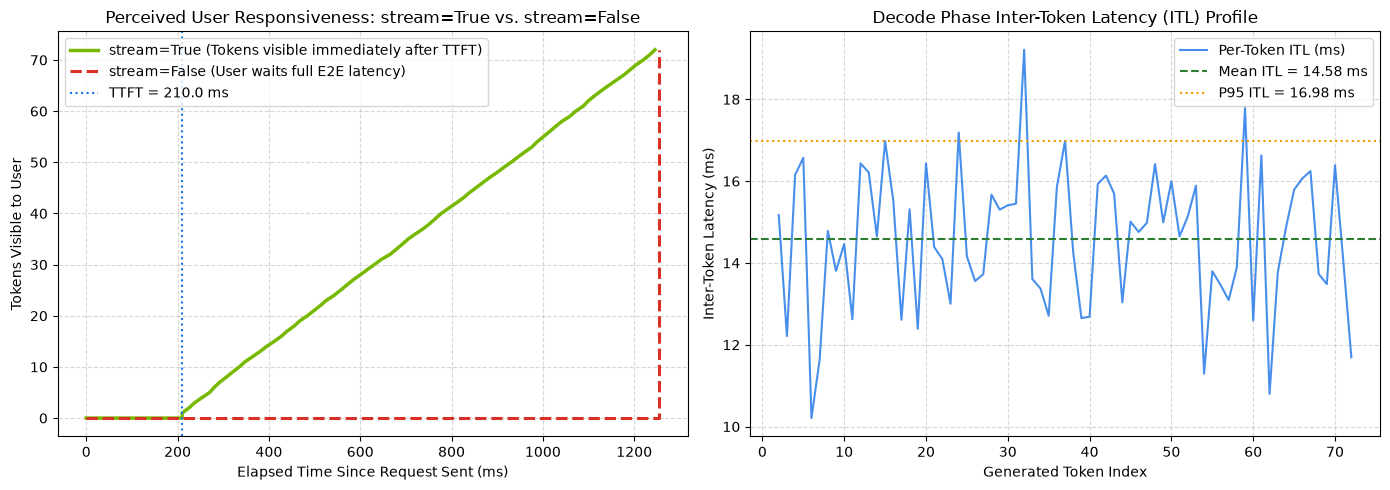

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Cumulative tokens visible to the user over time
cum_times = streaming_res["cumulative_times_ms"]
token_indices = np.arange(1, len(cum_times) + 1)
axes[0].plot([0, cum_times[0]] + cum_times, [0, 0] + list(token_indices),
             label="stream=True (Tokens visible immediately after TTFT)", color="#76B900", linewidth=2.5)
axes[0].plot([0, blocking_res["e2e_latency_ms"], blocking_res["e2e_latency_ms"]],
             [0, 0, blocking_res["num_tokens"]],
             label="stream=False (User waits full E2E latency)", color="#D93025", linestyle="--", linewidth=2.2)
axes[0].axvline(streaming_res["ttft_visible_ms"], color="#1A73E8", linestyle=":",
                label=f"TTFT = {streaming_res['ttft_visible_ms']} ms")
axes[0].set_xlabel("Elapsed Time Since Request Sent (ms)")
axes[0].set_ylabel("Tokens Visible to User")
axes[0].set_title("Perceived User Responsiveness: stream=True vs. stream=False")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Right plot: Inter-Token Latency (ITL) across generated token positions
itls = streaming_res["itl_series_ms"]
axes[1].plot(range(2, len(cum_times) + 1), itls, color="#1A73E8", alpha=0.8, label="Per-Token ITL (ms)")
axes[1].axhline(streaming_res["mean_itl_ms"], color="#2E7D32", linestyle="--",
                label=f"Mean ITL = {streaming_res['mean_itl_ms']} ms")
axes[1].axhline(streaming_res["p95_itl_ms"], color="#F29900", linestyle=":",
                label=f"P95 ITL = {streaming_res['p95_itl_ms']} ms")
axes[1].set_xlabel("Generated Token Index")
axes[1].set_ylabel("Inter-Token Latency (ms)")
axes[1].set_title("Decode Phase Inter-Token Latency (ITL) Profile")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
## 4. Experiment: How Input Prompt Length Impacts TTFT vs. ITL

In **Chapter 3**, the exam tip notes that:
- Increasing **input prompt length** (e.g., stuffing a 4,000-token RAG context into the prompt) increases the compute work in the **Prefill phase**, which directly increases **TTFT**.
- Increasing **`max_tokens` (output length)** increases the number of sequential steps in the **Decode phase**, which linearly increases **End-to-End Latency** while leaving **TTFT** unchanged!

Let's verify this relationship quantitatively across short, medium, and long input prompts.

In [4]:
def simulate_prompt_length_scaling():
    prompt_sizes = [64, 512, 2048, 4096]  # Input prompt tokens
    output_tokens = 100
    rows = []
    for p_toks in prompt_sizes:
        # Prefill scales with prompt tokens; Decode ITL stays nearly constant (plus slight KV cache growth)
        ttft_ms = 65.0 + 0.14 * p_toks
        itl_ms = 14.0 + 0.0005 * p_toks
        e2e_ms = ttft_ms + (output_tokens - 1) * itl_ms
        rows.append({
            "Input_Prompt_Tokens": p_toks,
            "Generated_Output_Tokens": output_tokens,
            "Prefill_TTFT_ms": round(ttft_ms, 1),
            "Decode_ITL_ms": round(itl_ms, 2),
            "End_to_End_Latency_ms": round(e2e_ms, 1),
        })
    return pd.DataFrame(rows)

df_scaling = simulate_prompt_length_scaling()
print("=== IMPACT OF INPUT PROMPT LENGTH ON TTFT VS. ITL ===")
print(df_scaling.to_string(index=False))

=== IMPACT OF INPUT PROMPT LENGTH ON TTFT VS. ITL ===
 Input_Prompt_Tokens  Generated_Output_Tokens  Prefill_TTFT_ms  Decode_ITL_ms  End_to_End_Latency_ms
                  64                      100             74.0          14.03                 1463.1
                 512                      100            136.7          14.26                 1548.0
                2048                      100            351.7          15.02                 1839.1
                4096                      100            638.4          16.05                 2227.2


---
## 5. Hands-On Exercises

### Exercise 1: Compute Latency SLA Compliance from Raw Timestamps
Suppose your production chatbot SLA requires:
- **TTFT $\le 400\text{ ms}$**
- **Mean ITL $\le 25\text{ ms}$** (equivalent to $\ge 40\text{ tokens/sec}$ during decode)

Given `t_send = 10.000` seconds and a list of token arrival timestamps `t_tokens = [10.310, 10.328, 10.345, 10.366, 10.384, 10.402]`, write a function `check_sla(t_send, t_tokens)` that calculates `ttft_ms`, `mean_itl_ms`, `e2e_ms`, and `sla_passed`.

In [5]:
# TODO: Complete Exercise 1
def check_sla(t_send: float, t_tokens: list) -> dict:
    pass

---
## 6. Reference Solutions

In [6]:
def check_sla_solution(t_send: float, t_tokens: list) -> dict:
    ttft_ms = (t_tokens[0] - t_send) * 1000.0
    e2e_ms = (t_tokens[-1] - t_send) * 1000.0
    itls_ms = [(t_tokens[i] - t_tokens[i - 1]) * 1000.0 for i in range(1, len(t_tokens))]
    mean_itl_ms = sum(itls_ms) / len(itls_ms)
    return {
        "ttft_ms": round(ttft_ms, 1),
        "mean_itl_ms": round(mean_itl_ms, 2),
        "e2e_ms": round(e2e_ms, 1),
        "decode_tok_per_s": round(1000.0 / mean_itl_ms, 1),
        "sla_passed": (ttft_ms <= 400.0) and (mean_itl_ms <= 25.0),
    }

sample_timestamps = [10.310, 10.328, 10.345, 10.366, 10.384, 10.402]
print("=== Exercise 1 Solution: SLA Check ===")
print(check_sla_solution(10.000, sample_timestamps))

=== Exercise 1 Solution: SLA Check ===
{'ttft_ms': 310.0, 'mean_itl_ms': 18.4, 'e2e_ms': 402.0, 'decode_tok_per_s': 54.3, 'sla_passed': True}


---
## 7. NCA-GENL Chapter 3 Review Takeaways

- **TTFT (Time to First Token):** Dominated by the **Prefill phase** (parallel processing of the input prompt). Long RAG contexts increase TTFT.
- **ITL (Inter-Token Latency):** Dominated by the **Decode phase** (sequential autoregressive generation, memory-bandwidth bound).
- **`stream=True`:** Uses Server-Sent Events (SSE) to deliver tokens as soon as TTFT completes, transforming user experience without changing total GPU compute time.